In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from sklearn.datasets import make_blobs
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, classification_report, silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.neighbors import LocalOutlierFactor
from sklearn.neighbors import NearestNeighbors
import seaborn as sns
from umap import UMAP

c:\Users\swart\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
rand = 42
sample_amount = 40_000
feature_amount = 20
blob_amount = 8
cluster_std = 1.2

X, _ = make_blobs(n_samples=sample_amount, n_features=feature_amount, centers=blob_amount, cluster_std=cluster_std, random_state=rand,)
df = pd.DataFrame(X, columns=[f"f{i}" for i in range(X.shape[1])])

In [3]:
def inject_noise(df, noise_frac, seed, n_features_affected=None):
    rng = np.random.default_rng(seed)
    noisy = df.copy()
    cols_all = df.columns
    n = len(df)
    n_noise = int(n * noise_frac)
    noise_idx = rng.choice(df.index, size=n_noise, replace=False)
    mask = np.zeros(n, dtype=int)
    for row_id in noise_idx:
        method = rng.integers(low=1, high=5, endpoint=True)
        mask[row_id] = method
        match (method):
            case 1:
                cols = cols_all
                for col in cols:
                    std = df[col].std()
                    direction = rng.choice([-1, 1])
                    noisy.loc[row_id, col] = df.loc[row_id, col] + direction * rng.uniform(8, 12) * std

            case 2:
                cols = rng.choice(cols_all, size=n_features_affected, replace=False)
                for col in cols:
                    std = df[col].std()
                    direction = rng.choice([-1, 1])
                    noisy.loc[row_id, col] = df.loc[row_id, col] + direction * rng.uniform(4, 6) * std

            case 3:
                wide_n = min(int(n_features_affected * 2.0), int(len(cols_all) * 0.5))
                cols = rng.choice(cols_all, size=wide_n, replace=False)
                donor_row = rng.choice(df.index[df.index != row_id])
                for col in cols:
                    noisy.loc[row_id, col] = df.loc[donor_row, col]

            case 4:
                wide_n = max(3, n_features_affected - 1)
                cols = rng.choice(cols_all, size=wide_n, replace=False)
                for col in cols:
                    donor_row = rng.choice(df.index[df.index != row_id])
                    noisy.loc[row_id, col] = df.loc[donor_row, col]

            case 5:
                narrow_n = max(3, int(n_features_affected * 0.8))
                cols = rng.choice(cols_all, size=narrow_n, replace=False)
                for col in cols:
                    std = df[col].std()
                    direction = rng.choice([-1, 1])
                    noisy.loc[row_id, col] = df.loc[row_id, col] + direction * rng.uniform(0.5, 0.85) * std

    return noisy, pd.Series(mask, index=df.index)

contam=0.2

noisy_df, true_mask = inject_noise(df, noise_frac=contam, n_features_affected=5, seed=rand)

In [ ]:
#AMOUNT OF NOISE
print(len(np.array(np.where(true_mask == True)).reshape(-1))/len(true_mask))

In [ ]:
rand = 42

gt_2015 = pd.read_csv("gt_2015.csv")
gt_2014 = pd.read_csv("gt_2014.csv")
gt_2013 = pd.read_csv("gt_2013.csv")
gt_2012 = pd.read_csv("gt_2012.csv")
gt_2011 = pd.read_csv("gt_2011.csv")
noisy_df = pd.concat([gt_2015, gt_2014, gt_2013, gt_2012, gt_2011])

In [ ]:
#HIST OF ALL FEATURES
noisy_df.hist(figsize=(15, 12), bins=100)
plt.show()

In [ ]:
plt.boxplot(noisy_df, showfliers = False)
plt.title("Box Plot")
plt.xlabel("Feature")
plt.ylabel("Range of values")
plt.show()

In [ ]:
numeric_df = df.select_dtypes(include=['number'])
plt.figure(figsize=(12, 8))
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show() # correlation heatmap 
correlation_matrix = numeric_df.corr()
correlation_matrix2 = df.corr()
weak_correlations = correlation_matrix[(correlation_matrix > -0.2) & (correlation_matrix < 0.2)]
strong_correlations = correlation_matrix2[(correlation_matrix2 > 0.6) | (correlation_matrix2 < -0.6)]
print(weak_correlations) #Which features have weak correlations with eachother
print(strong_correlations)

print(correlation_matrix)

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(noisy_df)
embedding = UMAP(n_components=2, random_state=rand, n_neighbors=30, min_dist=0.1).fit_transform(X_scaled)

print(f"UMAP embedding shape: {embedding.shape}")

plt.scatter(embedding[:, 0], embedding[:, 1], color="#264653")
plt.title("UMAP of noisy dataset")
plt.show()

In [ ]:
#PLOT FIRST FEATURE
try:
    colors = {
        0: "#264653",
        1: "#FF4D6D",
        2: "#FF9F1C",
        3: "#70E000",
        4: "#00B4D8",
        5: "#9B5DE5",
    }

    fig, ax = plt.subplots(figsize=(12, 6))

    for noise_type in range(6):
        mask = true_mask == noise_type

        ax.scatter(
            noisy_df.iloc[mask, 9] if hasattr(noisy_df.iloc[:, 9], "iloc")
            else noisy_df.iloc[:, 9][mask],
            noisy_df.index[mask],
            s=22,
            color=colors[noise_type],
            alpha=0.85,
            label="No noise" if noise_type == 0 else f"Noise type {noise_type}",
            edgecolors="none"
        )

    ax.set_ylim(0, 1_000)
    ax.set_xlabel("Entry value")
    ax.set_ylabel("Entry number")
    ax.set_title("Noise Types Across 1000 Entries for Feature 1")

    ax.legend(
        title="Category",
        loc="best",
        frameon=True,
    )

    ax.grid(True, linestyle="--", alpha=0.2)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()
    plt.show()
except:
    fig, ax = plt.subplots(figsize=(12, 6))

    ax.scatter(
        noisy_df.iloc[:, 9],
        noisy_df.index,
        s=22,
        color="#264653", 
        alpha=0.85,
        edgecolors="none"
    )

    ax.set_ylim(0, 1_000)
    ax.set_xlabel("Entry value")
    ax.set_ylabel("Entry number")
    ax.set_title("Entry Values Across 1000 Entries for Feature 1")

    ax.grid(True, linestyle="--", alpha=0.2)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()
    plt.show()

In [4]:
def impute_flagged_knn(data, flagged, knn_neighbors = 5):
    data = data.copy()
    clean = data.loc[~flagged]
    if flagged.sum() == 0 or len(clean) <= knn_neighbors:
        return data
    scaler = StandardScaler().fit(clean)
    nn = NearestNeighbors(n_neighbors=knn_neighbors).fit(scaler.transform(clean))
    _, idx = nn.kneighbors(scaler.transform(data.loc[flagged]))
    clean_vals = clean.to_numpy()
    imputed = clean_vals[idx].mean(axis=1)
    data.loc[flagged, :] = imputed
    return data

def metrics(flagged, mask=None):
    if mask is not None:
        flagged = np.asarray(flagged)
        n = [0, 0, 0, 0, 0, 0]
        m = [0, 0, 0, 0, 0, 0]
        for i in range(0, 6):
            m[i] = (mask == i).sum()
        for i in range(len(mask)):
            if flagged[i] == True:
                match mask.iloc[i]:
                    case 0:
                        n[0] += 1
                    case 1:
                        n[1] += 1
                    case 2:
                        n[2] += 1
                    case 3:
                        n[3] += 1
                    case 4:
                        n[4] += 1
                    case 5:
                        n[5] += 1
        tm = mask.squeeze().to_numpy()
        f = flagged.astype(int)
        results = []
        total_fp = ((tm == 0) & (f == 1)).sum()
        total_tn = ((tm == 0) & (f == 0)).sum()
        for i in range(1, 6):
            evaluate = (tm == i) | (tm == 0)
            tm_type = (tm[evaluate] == i).astype(int)
            f_type = f[evaluate]
            support = (tm_type == 1).sum()
            results.append({"noise type": f"noise {i}:", 
                            "TP": n[i],
                            "FN": m[i] - n[i],
                            "FP": "-",
                            "TN": "-",
                            "precision": precision_score(tm_type, f_type, zero_division=0), 
                            "recall": recall_score(tm_type, f_type, zero_division=0), 
                            "f1": f1_score(tm_type, f_type, zero_division=0),
                            "support": support})
        rdf = pd.DataFrame(results)
        total_row = {"noise type": f"total:", 
                            "TP": rdf["TP"].sum(),
                            "FN": rdf["FN"].sum(),
                            "FP": total_fp,
                            "TN": total_tn,
                            "precision": "-", 
                            "recall": "-", 
                            "f1": "-",
                            "support": rdf["support"].sum()}
        rdf = pd.concat([rdf, pd.DataFrame([total_row])], ignore_index=True)
        print(rdf)
    else:
        print(f"flagged: {flagged.sum()}")
  
def mitigate(data, flagged, mask=None, mitigation=1, knn_neighbors=5):
    flagged = np.asarray(flagged)
    match(mitigation):
        case 1: #remove
            keep = ~flagged
            data = data.loc[keep]
            if mask is not None:
                mask = mask[keep]
            print(f"removed: {flagged.sum()} / {len(flagged)}\n")
        case 2: #impute
            fixed_index = data.index[flagged]
            data = impute_flagged_knn(data, flagged, knn_neighbors=knn_neighbors)
            if mask is not None:
                mask = mask.copy()
                mask.loc[fixed_index] = 0
            print(f"imputed: {flagged.sum()} / {len(flagged)}\n")
    if mask is not None:
        return data, mask
    return data

def run_iqr(data, iqr_fence, iqr_col_ratio, mask=None):
    print("IQR:")
    suspects = np.zeros(len(data), dtype=int)
    for col in data.columns:
        Q1 = np.percentile(data[col], 25)
        Q3 = np.percentile(data[col], 75)
        IQR = Q3 - Q1
        lower, upper = Q1 - iqr_fence * IQR, Q3 + iqr_fence * IQR
        suspects += (data[col] < lower) | (data[col] > upper)
    flagged = (suspects > len(data.columns) * iqr_col_ratio).to_numpy()
    metrics(flagged=flagged, mask=mask)
    return flagged

def run_isolation_forest(data, isof_estimators, mask=None):
    print("ISOLATION FOREST:")
    model = IsolationForest(n_estimators=isof_estimators, contamination='auto', n_jobs=-1, random_state=rand)
    flagged = model.fit_predict(data) == -1
    metrics(flagged=flagged, mask=mask)
    return flagged

def run_kmeans(data, kmeans_init, kmeans_contam, mask=None, kmeans_clusters=None):
    print("K-MEANS:")
    scaled = StandardScaler().fit_transform(data)
    if kmeans_clusters is None:
        kmeans_clusters = 2
        best = 0
        while True:
            k_means = KMeans(n_clusters=kmeans_clusters, random_state=rand, init="k-means++", n_init=20)
            predicted_labels = k_means.fit_predict(scaled)
            silhouette = silhouette_score(scaled, predicted_labels)
            if silhouette < best:
                print(f"kmeans cluster amount found: {kmeans_clusters}")
                break
            else:
                kmeans_clusters += 1
                best = silhouette
    kmeans = KMeans(n_clusters=kmeans_clusters, random_state=rand, n_init=kmeans_init, init="k-means++")
    kmeans.fit(scaled)
    distances = np.min(kmeans.transform(scaled), axis=1)
    threshold = np.percentile(distances, (1 - kmeans_contam) * 100)
    flagged = distances > threshold
    metrics(flagged=flagged, mask=mask)
    return flagged

def run_dbscan(data, dbscan_eps, dbscan_min_samp, mask=None):
    print("DBSCAN:")
    scaled = StandardScaler().fit_transform(data)
    dbscan = DBSCAN(eps=dbscan_eps, min_samples=dbscan_min_samp, n_jobs=-1)
    flagged = dbscan.fit_predict(scaled) == -1
    metrics(flagged=flagged, mask=mask)
    return flagged

def run_lof(data, lof_neighbors, mask=None):
    print("LOF:")
    scaled = StandardScaler().fit_transform(data)
    lof = LocalOutlierFactor(n_neighbors=lof_neighbors, contamination='auto')
    flagged = lof.fit_predict(scaled) == -1
    metrics(flagged=flagged, mask=mask)
    return flagged

def pipeline(data, mask=None, clusters=None, contam=None, iqr_fence = 1.5, 
             iqr_col_ratio = 0.8, isof_estimators = 480, kmeans_init = 20, 
             kmeans_contam = None, dbscan_eps = 1.5, dbscan_min_samp = 20, 
             lof_neighbors = 20, knn_neighbors = 5): 
    if kmeans_contam is None:
        kmeans_contam = contam / 5 if contam is not None else 0
    if mask is None:
        flagged = run_iqr(data=data, iqr_fence=iqr_fence, iqr_col_ratio=iqr_col_ratio)
        r_sum_flagged = flagged.sum()
        print(f"total flagged: {r_sum_flagged}\n")
        data = mitigate(data=data, flagged=flagged, mitigation=1, knn_neighbors=knn_neighbors)
        nr_flagged = np.zeros(len(data), dtype=int)
        flagged = run_isolation_forest(data=data, isof_estimators=isof_estimators)
        nr_flagged = nr_flagged | flagged
        print(f"total flagged: {nr_flagged.sum() + r_sum_flagged}\n")
        flagged = run_kmeans(data=data, kmeans_clusters=clusters, kmeans_init=kmeans_init, kmeans_contam=kmeans_contam)
        nr_flagged = nr_flagged | flagged
        print(f"total flagged: {nr_flagged.sum() + r_sum_flagged}\n")
        flagged = run_dbscan(data=data, dbscan_eps=dbscan_eps, dbscan_min_samp=dbscan_min_samp)
        nr_flagged = nr_flagged | flagged
        print(f"total flagged: {nr_flagged.sum() + r_sum_flagged}\n")
        flagged = run_lof(data=data, lof_neighbors=lof_neighbors)
        nr_flagged = nr_flagged | flagged
        print(f"total flagged: {nr_flagged.sum() + r_sum_flagged}\n")
        final_flagged = nr_flagged > 0
        data = mitigate(data, final_flagged, mitigation=2, knn_neighbors=knn_neighbors)
        return data

    o_mask = mask.copy()
    flagged = run_iqr(data=data, iqr_fence=iqr_fence, iqr_col_ratio=iqr_col_ratio, mask=mask)
    r_sum_flagged = flagged.sum()
    print(f"total flagged: {r_sum_flagged}\n")
    data, mask = mitigate(data=data, flagged=flagged, mask=mask, mitigation=1, knn_neighbors=knn_neighbors)
    nr_flagged = np.zeros(len(data), dtype=int)
    flagged = run_isolation_forest(data=data, isof_estimators=isof_estimators, mask=mask)
    nr_flagged = nr_flagged | flagged
    print(f"total flagged: {nr_flagged.sum() + r_sum_flagged}\n")
    flagged = run_kmeans(data=data, kmeans_clusters=clusters, kmeans_init=kmeans_init, kmeans_contam=kmeans_contam, mask=mask)
    nr_flagged = nr_flagged | flagged
    print(f"total flagged: {nr_flagged.sum() + r_sum_flagged}\n")
    flagged = run_dbscan(data=data, dbscan_eps=dbscan_eps, dbscan_min_samp=dbscan_min_samp, mask=mask)
    nr_flagged = nr_flagged | flagged
    print(f"total flagged: {nr_flagged.sum() + r_sum_flagged}\n")
    flagged = run_lof(data=data, lof_neighbors=lof_neighbors, mask=mask)
    nr_flagged = nr_flagged | flagged
    print(f"total flagged: {nr_flagged.sum() + r_sum_flagged}\n")
    final_flagged = nr_flagged > 0
    data, mask = mitigate(data, final_flagged, mask=mask, mitigation=2, knn_neighbors=knn_neighbors)
    final_f = np.zeros(len(o_mask), dtype=bool)
    shift = 0
    for i in range(0, len(o_mask)):
        if (i not in mask.index):
            final_f[i] = True
            shift += 1
        else:   
            final_f[i] = final_flagged[i - shift]
    print("ALL METHODS: ")
    print("classification report: ")
    print(classification_report(o_mask != 0, final_f, labels=[False, True], target_names=["Normal", "Outlier"], zero_division=0))
    print("confusion matrix: ")
    print(f"{confusion_matrix(o_mask != 0, final_f, labels=[False, True])}\n")
    metrics(flagged=final_f, mask=o_mask)
    return data, mask

In [5]:
try:
    data = noisy_df.copy()
    mask = true_mask.copy()
    clean_df, mask = pipeline(data, mask, contam=contam)
except:
    data = noisy_df.copy()
    clean_df = pipeline(data)

IQR:
  noise type    TP    FN FP     TN precision recall   f1  support
0   noise 1:  1564     0  -      -       1.0    1.0  1.0     1564
1   noise 2:     0  1683  -      -       0.0    0.0  0.0     1683
2   noise 3:     0  1587  -      -       0.0    0.0  0.0     1587
3   noise 4:     0  1574  -      -       0.0    0.0  0.0     1574
4   noise 5:     0  1592  -      -       0.0    0.0  0.0     1592
5     total:  1564  6436  0  32000         -      -    -     8000
total flagged: 1564

removed: 1564 / 40000

ISOLATION FOREST:
  noise type    TP    FN FP     TN precision    recall        f1  support
0   noise 1:     0     0  -      -       0.0       0.0       0.0        0
1   noise 2:  1682     1  -      -       1.0  0.999406  0.999703     1683
2   noise 3:     0  1587  -      -       0.0       0.0       0.0     1587
3   noise 4:     0  1574  -      -       0.0       0.0       0.0     1574
4   noise 5:     0  1592  -      -       0.0       0.0       0.0     1592
5     total:  1682  4754  0

In [6]:
def get_cluster(data):
    data = data.copy()
    data = StandardScaler().fit_transform(data)
    kmeans_clusters = 2
    best = 0
    while True:
        k_means = KMeans(n_clusters=kmeans_clusters, random_state=rand, init="k-means++", n_init=20)
        predicted_labels = k_means.fit_predict(data)
        silhouette = silhouette_score(data, predicted_labels)
        if silhouette < best:
            print(f"kmeans cluster amount found: {kmeans_clusters}")
            break
        else:
            kmeans_clusters += 1
            best = silhouette
    return kmeans_clusters
    
def end_kmeans(data, clusters):
    data = data.copy()
    data = StandardScaler().fit_transform(data)
    kmeans = KMeans(n_clusters=clusters, n_init='auto')
    kmeans_pred = kmeans.fit_predict(data)
    return kmeans_pred, data

clusters = get_cluster(clean_df)

try:
    o_pred, o_norm = end_kmeans(df, clusters)
except:
    pass
n_pred, n_norm = end_kmeans(noisy_df, clusters)
c_pred, c_norm = end_kmeans(clean_df, clusters)

kmeans cluster amount found: 9


In [7]:
try:
    o_ss = silhouette_score(o_norm, o_pred)
    o_dbi = davies_bouldin_score(o_norm, o_pred)
    o_chi = calinski_harabasz_score(o_norm, o_pred)
except:
    pass

n_ss = silhouette_score(n_norm, n_pred)
n_dbi = davies_bouldin_score(n_norm, n_pred)
n_chi = calinski_harabasz_score(n_norm, n_pred)

c_ss = silhouette_score(c_norm, c_pred)
c_dbi = davies_bouldin_score(c_norm, c_pred)
c_chi = calinski_harabasz_score(c_norm, c_pred)

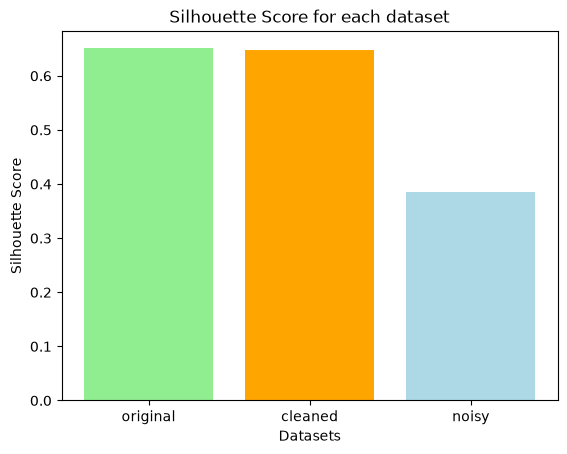

percentage increase in Silhouette Score for clean compared to noisy: 68.16%
percentage increase in Silhouette Score for original compared to noisy: 69.03%
percentage increase in Silhouette Score for origninal compared to clean: 0.51%


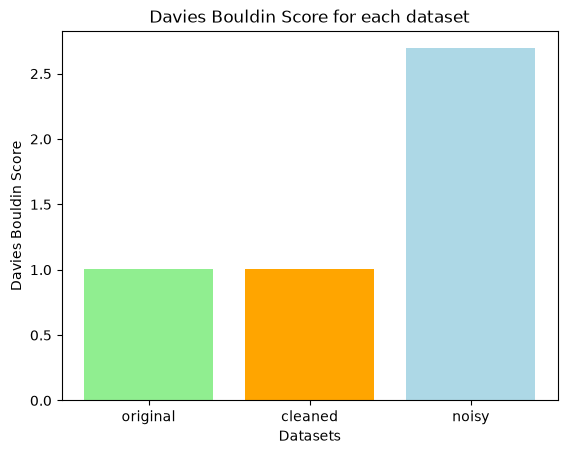

percentage decrease in Davies Bouldin Score for clean compared to noisy: 62.55%
percentage decrease in Davies Bouldin Score for original compared to noisy: 62.58%
percentage decrease in Davies Bouldin Score for origninal compared to clean: 0.08%


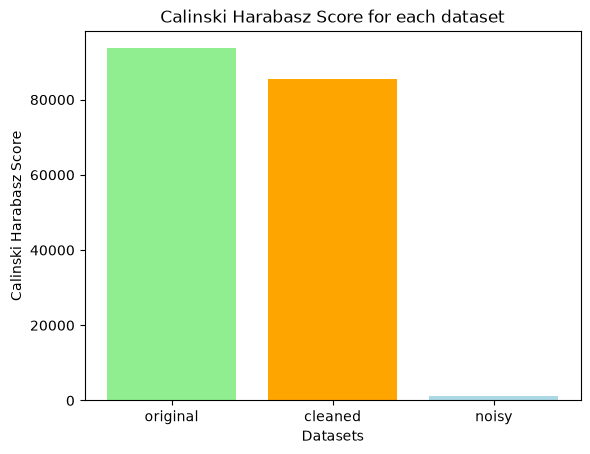

percentage increase in Calinski Harabasz Score for clean compared to noisy: 6492.34%
percentage increase in Calinski Harabasz Score for original compared to noisy: 7116.34%
percentage increase in Calinski Harabasz Score for origninal compared to clean: 9.47%


In [8]:
try:
    plt.bar(['original', 'cleaned', 'noisy'], [o_ss, c_ss, n_ss], color=['lightgreen', 'orange', 'lightblue'])
    plt.title("Silhouette Score for each dataset")
    plt.xlabel("Datasets")
    plt.ylabel("Silhouette Score")
    plt.show()
    print(f"percentage increase in Silhouette Score for clean compared to noisy: {round((c_ss - n_ss) / n_ss * 100, 2)}%")
    print(f"percentage increase in Silhouette Score for original compared to noisy: {round((o_ss - n_ss) / n_ss * 100, 2)}%")
    print(f"percentage increase in Silhouette Score for origninal compared to clean: {round((o_ss - c_ss) / c_ss * 100, 2)}%")

    plt.bar(['original', 'cleaned', 'noisy'], [o_dbi, c_dbi, n_dbi], color=['lightgreen', 'orange', 'lightblue'])
    plt.title("Davies Bouldin Score for each dataset")
    plt.xlabel("Datasets")
    plt.ylabel("Davies Bouldin Score")
    plt.show()
    print(f"percentage decrease in Davies Bouldin Score for clean compared to noisy: {round((n_dbi - c_dbi) / n_dbi * 100, 2)}%")
    print(f"percentage decrease in Davies Bouldin Score for original compared to noisy: {round((n_dbi - o_dbi) / n_dbi * 100, 2)}%")
    print(f"percentage decrease in Davies Bouldin Score for origninal compared to clean: {round((c_dbi - o_dbi) / c_dbi * 100, 2)}%")


    plt.bar(['original', 'cleaned', 'noisy'], [o_chi, c_chi, n_chi], color=['lightgreen', 'orange', 'lightblue'])
    plt.title("Calinski Harabasz Score for each dataset")
    plt.xlabel("Datasets")
    plt.ylabel("Calinski Harabasz Score")
    plt.show()
    print(f"percentage increase in Calinski Harabasz Score for clean compared to noisy: {round((c_chi - n_chi) / n_chi * 100, 2)}%")
    print(f"percentage increase in Calinski Harabasz Score for original compared to noisy: {round((o_chi - n_chi) / n_chi * 100, 2)}%")
    print(f"percentage increase in Calinski Harabasz Score for origninal compared to clean: {round((o_chi - c_chi) / c_chi * 100, 2)}%")

except:
    plt.bar(['cleaned', 'noisy'], [c_ss, n_ss], color=['orange', 'lightblue'])
    plt.title("Silhouette Score for each dataset")
    plt.xlabel("Datasets")
    plt.ylabel("Silhouette Score")
    plt.show()
    print((c_ss - n_ss) / n_ss * 100)

    plt.bar(['cleaned', 'noisy'], [c_dbi, n_dbi], color=['orange', 'lightblue'])
    plt.title("Davies Bouldin Score for each dataset")
    plt.xlabel("Datasets")
    plt.ylabel("Davies Bouldin Score")
    plt.show()
    print((n_dbi - c_dbi) / n_dbi * 100)

    plt.bar(['cleaned', 'noisy'], [c_chi, n_chi], color=['orange', 'lightblue'])
    plt.title("Calinski Harabasz Score for each dataset")   
    plt.xlabel("Datasets")
    plt.ylabel("Calinski Harabasz Score")
    plt.show()
    print((c_chi - n_chi) / n_chi * 100)